In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


def load_csv_matrix(file_path, freq_min, dataset):
    df = pd.read_csv(file_path)

    if "timestamp" not in df.columns:
        raise ValueError("The file must contain a column named 'timestamp'.")

    df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y%m%d-%H%M")

    df = (
        df.drop_duplicates(subset="timestamp")
        .set_index("timestamp")
        .sort_index()
    )

    numeric_columns = df.select_dtypes(include=[np.number]).columns
    df = df[numeric_columns]

    full_index = pd.date_range(
        start=df.index.min(),
        end=df.index.max(),
        freq=f"{freq_min}min"
    )

    df = df.reindex(full_index)
    df.index.name = "timestamp"

    if dataset.lower() == "geant":
        # In GEANT, a missing matrix appears as an entire row of zeros.
        # Individual zeros are preserved because they may represent
        # very small or rounded traffic values.
        empty_rows = df.eq(0).all(axis=1)
        df.loc[empty_rows, :] = np.nan

    return df


def get_shortest_segments(variation, n=2):
    valid = ~variation.isna().all(axis=1)
    groups = (valid != valid.shift()).cumsum()

    segments = []

    for _, block in valid.groupby(groups):
        if block.iloc[0]:
            segments.append({
                "start": block.index[0],
                "end": block.index[-1],
                "samples": len(block)
            })

    segments.sort(key=lambda x: x["samples"])

    print(f"\n{n} shortest segments after seasonal differencing:")
    print("-" * 60)

    for segment in segments[:n]:
        print(
            f"{segment['start']} to {segment['end']} | "
            f"{segment['samples']} samples"
        )

    return segments[:n]


def seasonal_difference(df, period="7D"):
    """
    Computes seasonal differences independently for each continuous
    data fragment.

    Difference:
        current value - value at the same time in the previous week
    """

    variation = pd.DataFrame(
        index=df.index,
        columns=df.columns,
        dtype=float
    )

    gaps = df.isna().all(axis=1)
    groups = (gaps != gaps.shift()).cumsum()

    fragment_count = 0

    for _, block in gaps.groupby(groups):
        # Skip gap blocks
        if block.iloc[0]:
            continue

        fragment_index = block.index
        fragment = df.loc[fragment_index]

        fragment_count += 1

        reference = fragment.shift(freq=period)
        fragment_variation = fragment - reference

        variation.loc[fragment_index, :] = fragment_variation

    print(f"Continuous fragments processed: {fragment_count}")

    return variation


def diagnose_gaps(df, variation):
    original_gaps = df.isna().all(axis=1)
    variation_gaps = variation.isna().all(axis=1)

    print("Gap summary")
    print("-" * 60)
    print(f"Total timestamps in dataset: {len(df)}")
    print(f"Gaps in original dataset: {original_gaps.sum()}")
    print(f"Gaps in seasonal difference: {variation_gaps.sum()}")

    print("\nGap intervals in original dataset:")
    show_gap_intervals(original_gaps)

    print("\nGap intervals in seasonal difference:")
    show_gap_intervals(variation_gaps)


def show_gap_intervals(mask):
    if mask.sum() == 0:
        print("No gaps found.")
        return

    groups = (mask != mask.shift()).cumsum()

    for _, block in mask.groupby(groups):
        if block.iloc[0]:
            start = block.index[0]
            end = block.index[-1]
            samples = len(block)

            print(f"{start} to {end} | {samples} samples")


def plot_seasonal_variation(df, variation, dataset_name, top_n=10):
    top_columns = (
        df.mean(skipna=True)
        .sort_values(ascending=False)
        .head(top_n)
        .index
    )

    original_gaps = df.isna().all(axis=1)
    variation_gaps = variation.isna().all(axis=1)

    plt.figure(figsize=(16, 6))

    for column in top_columns:
        plt.plot(
            variation.index,
            variation[column],
            linewidth=1,
            alpha=0.7,
            label=column,
        )

    # Original dataset gaps
    for timestamp in df.index[original_gaps]:
        plt.axvline(
            timestamp,
            color="red",
            alpha=0.08,
            linewidth=0.7
        )

    # Additional gaps introduced by seasonal differencing
    additional_gaps = variation_gaps & ~original_gaps

    for timestamp in variation.index[additional_gaps]:
        plt.axvline(
            timestamp,
            color="orange",
            alpha=0.04,
            linewidth=0.7,
        )

    plt.axhline(
        y=0,
        color="black",
        linestyle="--",
        linewidth=1.2,
    )

    plt.title(
        f"Seasonal Variation: {dataset_name} - Top {top_n} Streams",
        fontsize=26
    )
    plt.xlabel("Time", fontsize=26)
    plt.ylabel("Seasonal Difference", fontsize=26)


    plt.xticks(fontsize=14)  # timestamps do eixo X
    plt.yticks(fontsize=14)  # valores do eixo Y

    plt.grid(True, alpha=0.25)
    plt.legend(fontsize=18, ncol=2)
    plt.tight_layout()
    plt.show()


def plot_aggregated_traffic(df, dataset_name):
    aggregated = df.sum(axis=1, skipna=True)

    # If the entire row is missing, aggregated traffic must also be NaN.
    gaps = df.isna().all(axis=1)
    aggregated[gaps] = np.nan

    plt.figure(figsize=(16, 6))

    plt.plot(
        aggregated.index,
        aggregated,
        label="Aggregated Traffic",
        color="blue",
        linewidth=1
    )

    for timestamp in df.index[gaps]:
        plt.axvline(
            timestamp,
            color="red",
            alpha=0.1,
            linewidth=0.7
        )

    plt.title(f"{dataset_name} Traffic Time Series with Gaps")
    plt.xlabel("Time")
    plt.ylabel("Aggregated Traffic - All Streams")

    plt.yscale("log")
    plt.grid(
        True,
        which="both",
        linestyle="--",
        alpha=0.5
    )
    plt.legend()
    plt.tight_layout()
    plt.show()


def process_geant():
    file_path = "./datasets/geant_demand_matrix.csv"

    df_geant = load_csv_matrix(
        file_path=file_path,
        freq_min=15,
        dataset="geant"
    )

    geant_variation = seasonal_difference(
        df_geant,
        period="7D"
    )

    print("\nGEANT seasonal difference diagnostics:")
    diagnose_gaps(df_geant, geant_variation)

    plot_aggregated_traffic(
        df=df_geant,
        dataset_name="GEANT"
    )

    plot_seasonal_variation(
        df=df_geant,
        variation=geant_variation,
        dataset_name="GEANT",
        top_n=10
    )

    Path("./outputs").mkdir(exist_ok=True)

    df_geant.to_csv(
        "./outputs/geant_processed_with_gaps.csv"
    )

    geant_variation.to_csv(
        "./outputs/geant_seasonal_difference_with_gaps.csv"
    )

    return df_geant, geant_variation


def process_abilene():
    file_path = "./datasets/abilene_demand_matrix.csv"

    df_abilene = load_csv_matrix(
        file_path=file_path,
        freq_min=5,
        dataset="abilene"
    )

    abilene_variation = seasonal_difference(
        df_abilene,
        period="7D"
    )

    print("\nABILENE seasonal difference diagnostics:")
    diagnose_gaps(df_abilene, abilene_variation)

    plot_aggregated_traffic(
        df=df_abilene,
        dataset_name="ABILENE"
    )

    plot_seasonal_variation(
        df=df_abilene,
        variation=abilene_variation,
        dataset_name="ABILENE",
        top_n=10
    )

    Path("./outputs").mkdir(exist_ok=True)

    df_abilene.to_csv(
        "./outputs/abilene_processed_with_gaps.csv"
    )

    abilene_variation.to_csv(
        "./outputs/abilene_seasonal_difference_with_gaps.csv"
    )

    return df_abilene, abilene_variation

Continuous fragments processed: 7

GEANT seasonal difference diagnostics:
Gap summary
------------------------------------------------------------
Total timestamps in dataset: 11460
Gaps in original dataset: 688
Gaps in seasonal difference: 4434

Gap intervals in original dataset:
2005-05-04 15:00:00 to 2005-05-04 15:15:00 | 2 samples
2005-05-19 10:00:00 to 2005-05-19 16:30:00 | 27 samples
2005-05-27 17:00:00 to 2005-05-27 17:45:00 | 4 samples
2005-05-31 15:45:00 to 2005-05-31 15:45:00 | 1 samples
2005-05-31 18:45:00 to 2005-05-31 19:00:00 | 2 samples
2005-06-28 16:45:00 to 2005-07-03 10:30:00 | 456 samples
2005-07-24 05:45:00 to 2005-07-25 14:30:00 | 132 samples
2005-08-31 08:00:00 to 2005-08-31 23:45:00 | 64 samples

Gap intervals in seasonal difference:
2005-05-04 15:00:00 to 2005-05-11 15:15:00 | 674 samples
2005-05-19 10:00:00 to 2005-05-26 16:30:00 | 699 samples
2005-05-27 17:00:00 to 2005-06-07 19:00:00 | 1065 samples
2005-06-28 16:45:00 to 2005-07-10 10:30:00 | 1128 samples
200

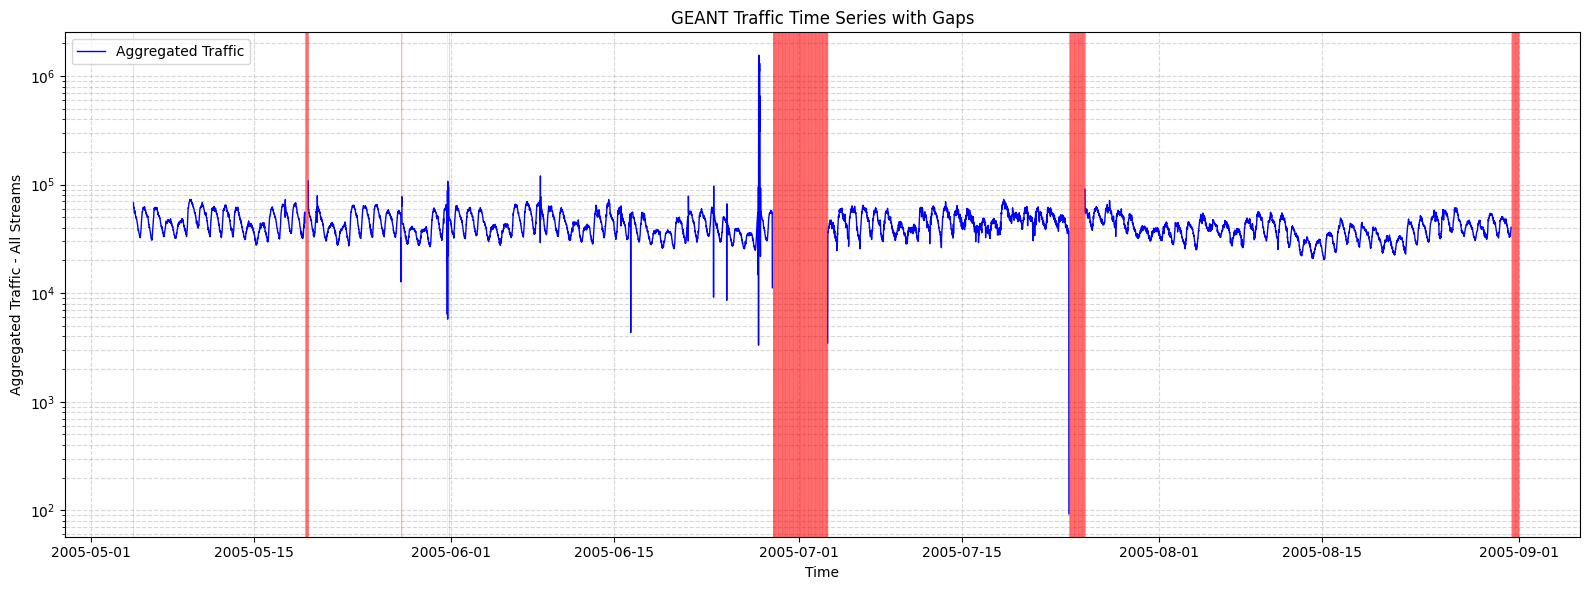

/tmp/ipykernel_84654/1464538274.py:206: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


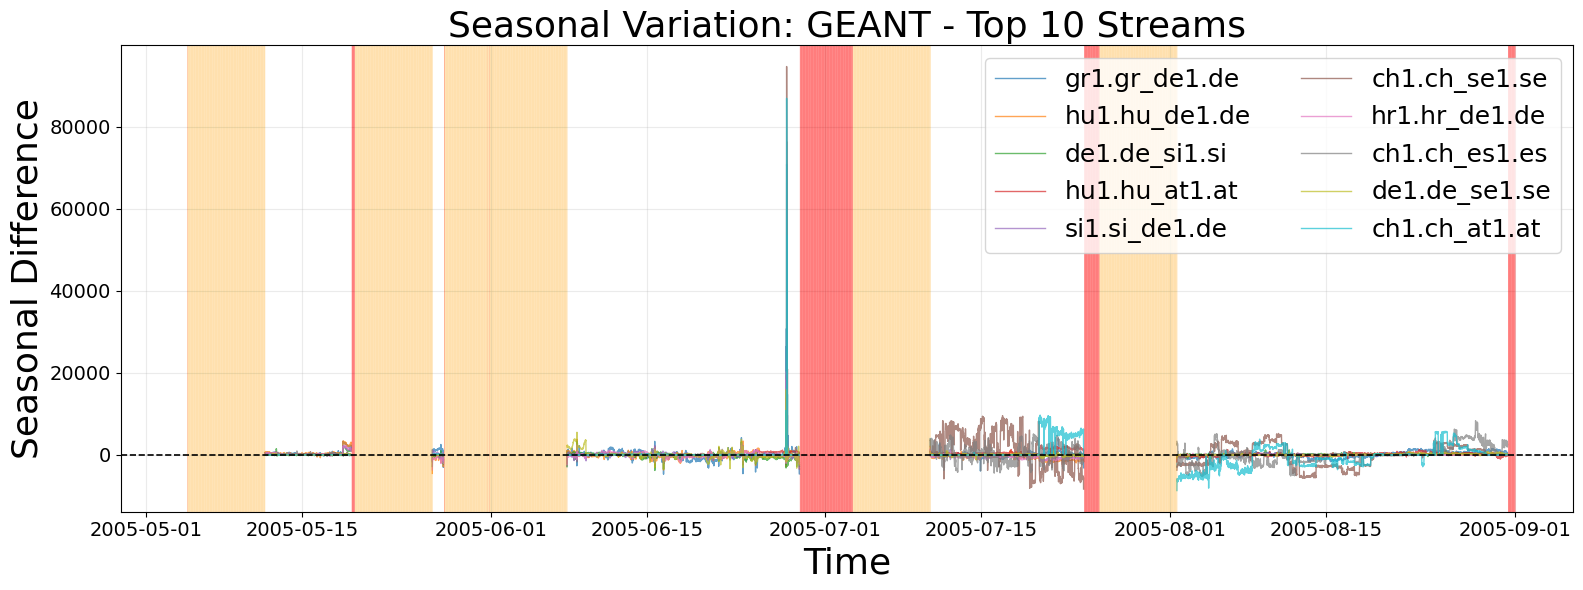

Continuous fragments processed: 5

ABILENE seasonal difference diagnostics:
Gap summary
------------------------------------------------------------
Total timestamps in dataset: 55872
Gaps in original dataset: 7776
Gaps in seasonal difference: 17856

Gap intervals in original dataset:
2004-03-15 00:00:00 to 2004-04-01 23:55:00 | 5184 samples
2004-04-16 00:00:00 to 2004-04-21 23:55:00 | 1728 samples
2004-04-29 00:00:00 to 2004-04-30 23:55:00 | 576 samples
2004-08-20 00:00:00 to 2004-08-20 23:55:00 | 288 samples

Gap intervals in seasonal difference:
2004-03-01 00:00:00 to 2004-03-07 23:55:00 | 2016 samples
2004-03-15 00:00:00 to 2004-04-08 23:55:00 | 7200 samples
2004-04-16 00:00:00 to 2004-05-07 23:55:00 | 6336 samples
2004-08-20 00:00:00 to 2004-08-27 23:55:00 | 2304 samples


/tmp/ipykernel_84654/1464538274.py:247: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


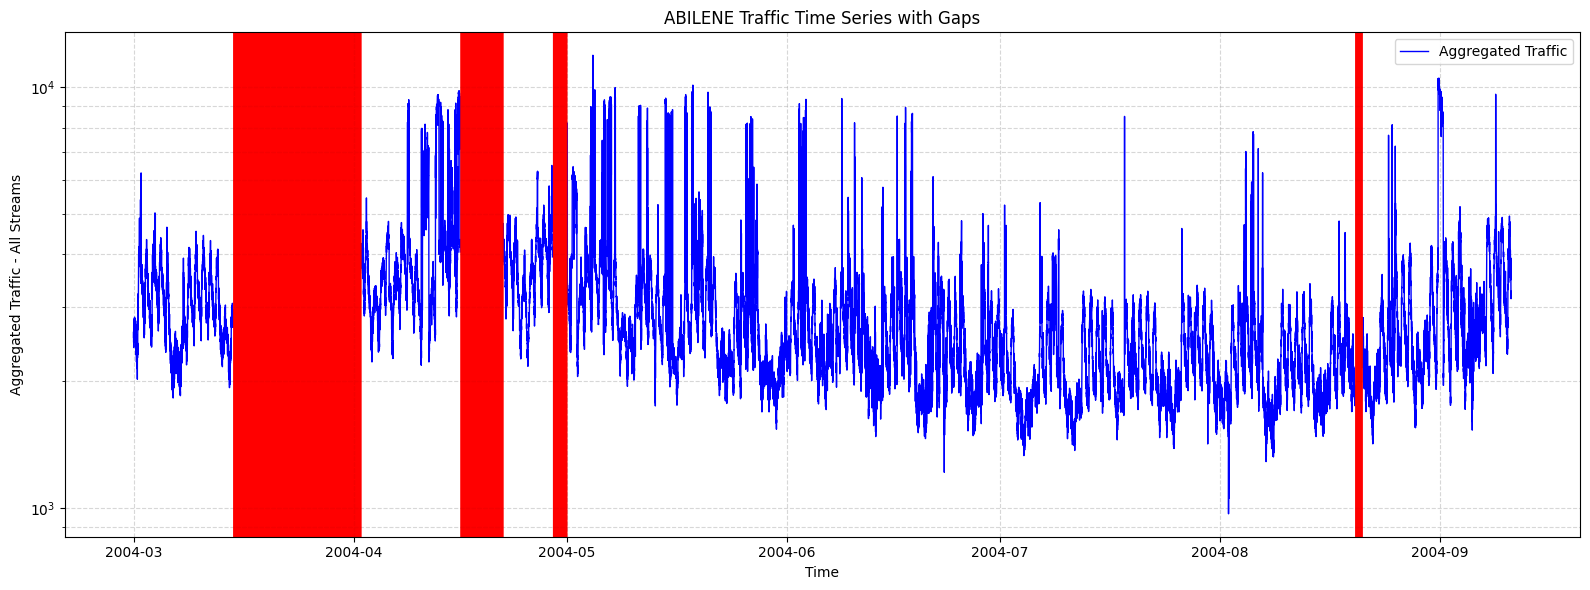

/tmp/ipykernel_84654/1464538274.py:206: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/home/abrahao/miniconda3/envs/online/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


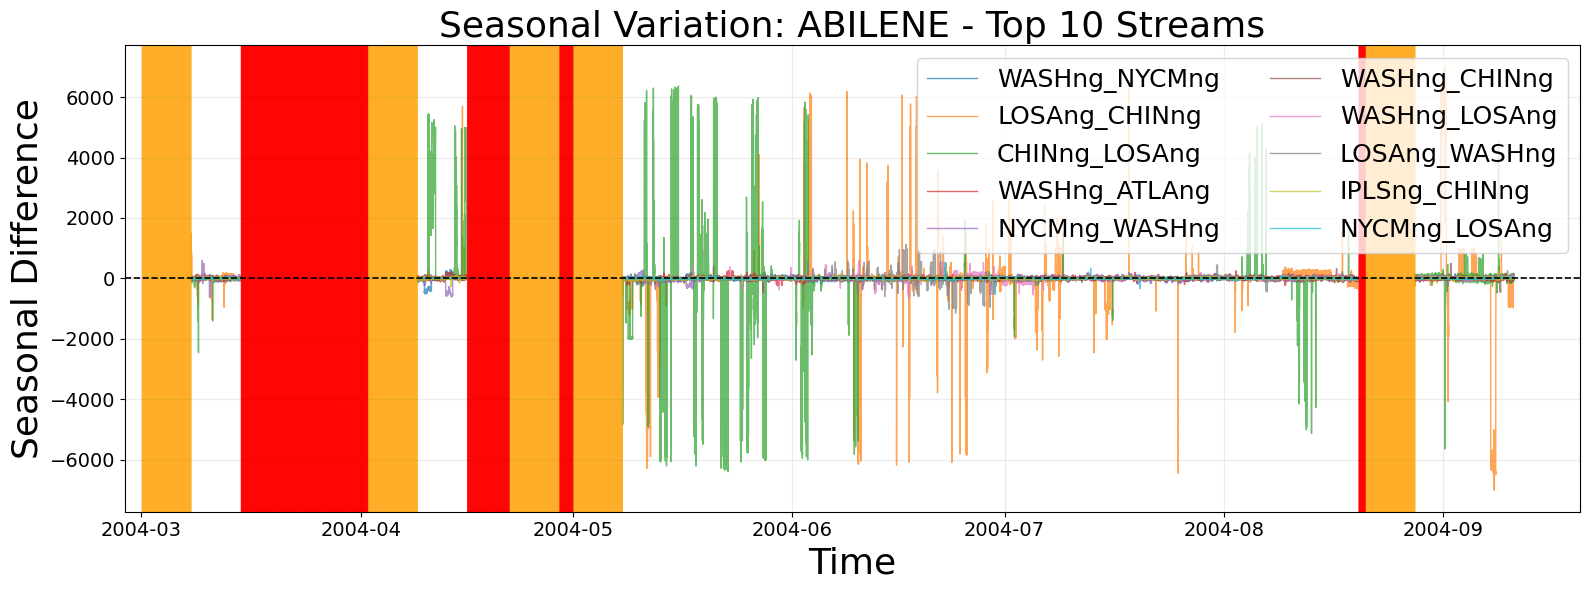

In [2]:
df_geant, geant_variation = process_geant()
df_abilene, abilene_variation = process_abilene()

In [3]:
shortest_geant = get_shortest_segments(geant_variation, n=2)
shortest_abilene = get_shortest_segments(abilene_variation, n=2)


2 shortest segments after seasonal differencing:
------------------------------------------------------------
2005-05-26 16:45:00 to 2005-05-27 16:45:00 | 97 samples
2005-05-11 15:30:00 to 2005-05-19 09:45:00 | 746 samples

2 shortest segments after seasonal differencing:
------------------------------------------------------------
2004-03-08 00:00:00 to 2004-03-14 23:55:00 | 2016 samples
2004-04-09 00:00:00 to 2004-04-15 23:55:00 | 2016 samples


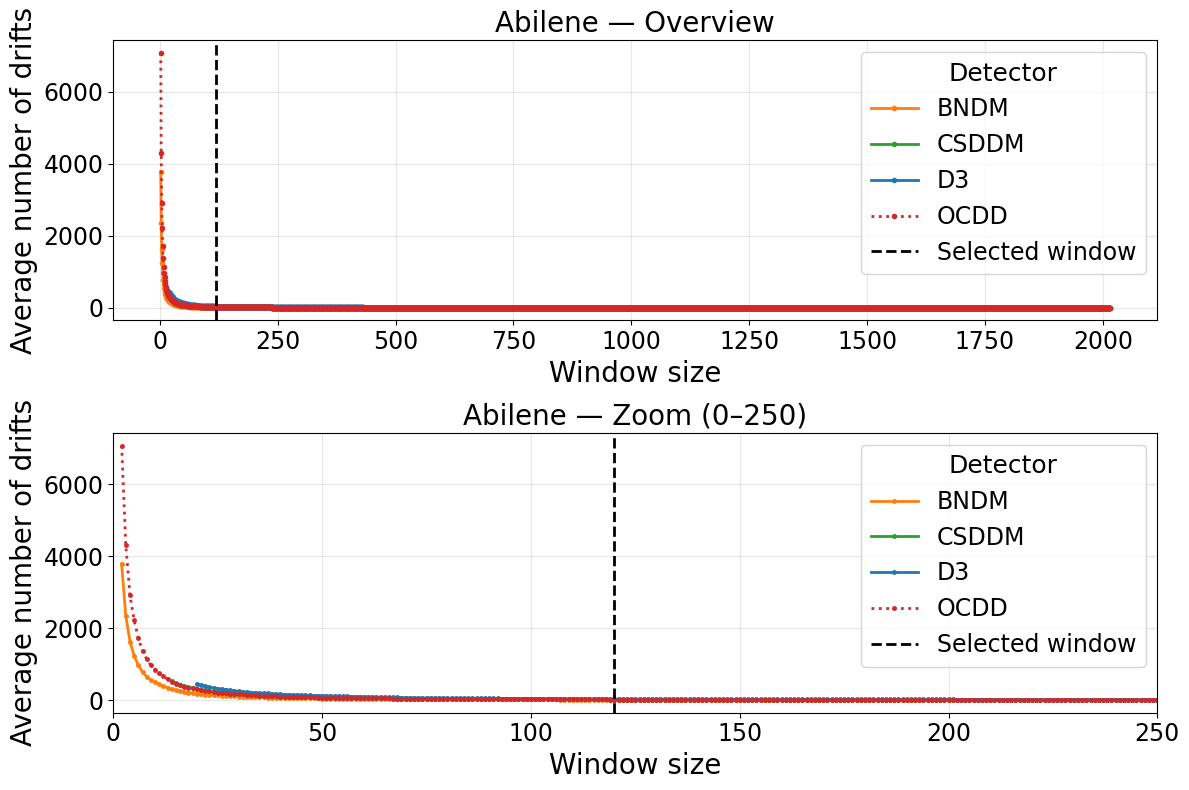

Gráfico salvo em: plots/abilene_zoom.png


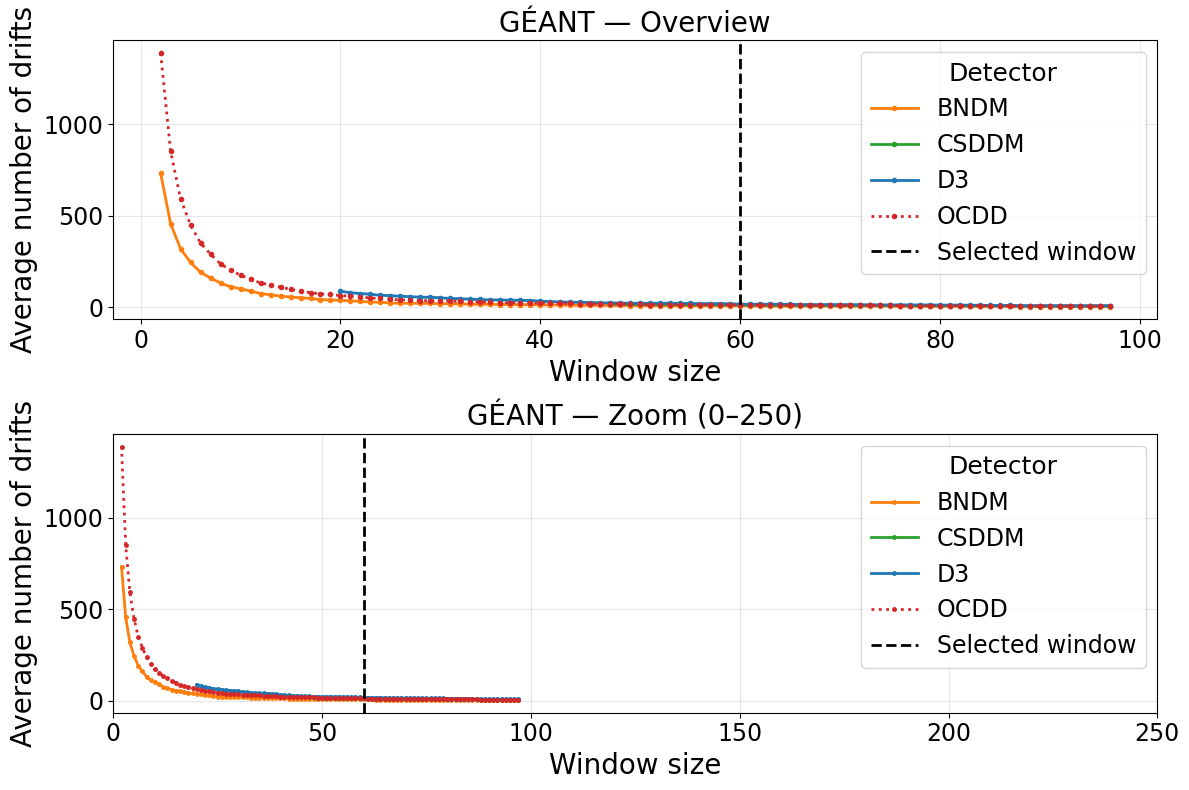

Gráfico salvo em: plots/geant_zoom.png


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==============================
# CONFIG
# ==============================

FILES = {
    "Abilene": "./results_sem_log//outputs/abilene_diferenca_sazonal_sem_log_com_lacunas/abilene_summary.csv",
    "GÉANT": "./results_sem_log//outputs/geant_diferenca_sazonal_sem_log_com_lacunas/geant_summary.csv",
}

OUT_DIR = Path("./plots")
OUT_DIR.mkdir(exist_ok=True)

# 🔎 intervalo de zoom
X_MIN = 0
X_MAX = 250

# estilos (cor + linha + marcador)
STYLES = {
    "D3":    {"color": "#1f77b4", "linestyle": "-",  "marker": "."},
    "BNDM":  {"color": "#ff7f0e", "linestyle": "-", "marker": "."},
    "CSDDM": {"color": "#2ca02c", "linestyle": "-", "marker": "."},
    "OCDD":  {"color": "#d62728", "linestyle": ":",  "marker": "."},
}

SELECTED_WINDOWS = {
    "Abilene": 120,
    "GÉANT": 60,
}

# ==============================
# LOOP DATASETS
# ==============================

for dataset_name, path in FILES.items():
    df = pd.read_csv(path)

    # média + desvio padrão entre seeds
    grouped = (
        df.groupby(["detector", "window"], as_index=False)
          .agg(mean_drifts=("n_drifts", "mean"),
               std_drifts=("n_drifts", "std"),
               runs=("n_drifts", "count"))
    )

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

    for detector in sorted(grouped["detector"].unique()):
        sub = grouped[grouped["detector"] == detector].sort_values("window")

        style = STYLES.get(detector, {})
        color = style.get("color")

        # ======================
        # GRÁFICO COMPLETO
        # ======================
        ax1.plot(
            sub["window"],
            sub["mean_drifts"],
            label=detector,
            linewidth=2,
            **style
        )

        if sub["std_drifts"].notna().any():
            ax1.fill_between(
                sub["window"],
                sub["mean_drifts"] - sub["std_drifts"],
                sub["mean_drifts"] + sub["std_drifts"],
                color=color,
                alpha=0.2
            )

        # ======================
        # ZOOM
        # ======================
        sub_zoom = sub[
            (sub["window"] >= X_MIN) &
            (sub["window"] <= X_MAX)
        ]

        if sub_zoom.empty:
            print(f"{dataset_name} | {detector} sem dados no zoom")
            continue

        ax2.plot(
            sub_zoom["window"],
            sub_zoom["mean_drifts"],
            label=detector,
            linewidth=2,
            markersize=5,
            **style
        )

        if sub_zoom["std_drifts"].notna().any():
            ax2.fill_between(
                sub_zoom["window"],
                sub_zoom["mean_drifts"] - sub_zoom["std_drifts"],
                sub_zoom["mean_drifts"] + sub_zoom["std_drifts"],
                color=color,
                alpha=0.2
            )

    # ==============================
    # JANELA SELECIONADA
    # ==============================

    selected_window = SELECTED_WINDOWS[dataset_name]

    ax1.axvline(
        selected_window,
        color="black",
        linestyle="--",
        linewidth=2,
        label="Selected window"
    )

    ax2.axvline(
        selected_window,
        color="black",
        linestyle="--",
        linewidth=2,
        label="Selected window"
    )

    # ==============================
    # ESTILO
    # ==============================

    ax1.set_title(f"{dataset_name} — Overview", fontsize=20)
    ax2.set_title(f"{dataset_name} — Zoom ({X_MIN}–{X_MAX})", fontsize=20)

    for ax in [ax1, ax2]:
        ax.set_xlabel("Window size", fontsize=20)
        ax.set_ylabel("Average number of drifts", fontsize=20)

        # tamanho dos valores dos eixos X e Y
        ax.tick_params(axis="x", labelsize=17)
        ax.tick_params(axis="y", labelsize=17)

        ax.grid(True, alpha=0.3)
        # Legend
        ax.legend(
            title="Detector",
            fontsize=17,
            title_fontsize=18,
            loc="best",
            frameon=True
        )



    ax2.set_xlim(X_MIN, X_MAX)

    plt.tight_layout()

    # ==============================
    # SALVAR
    # ==============================

    out_path = OUT_DIR / f"{dataset_name.lower().replace('é', 'e')}_zoom.png"
    plt.savefig(out_path, dpi=300)

    plt.show()

    print(f"Gráfico salvo em: {out_path}")


Dataset: Abilene
Tamanho série original: 55872
Tamanho série detector sem NaN: 38016
D3     | window= 120 | drifts plotados=27
BNDM   | window= 120 | drifts plotados=9
CSDDM  | window= 120 | drifts plotados=12
OCDD   | window= 120 | drifts plotados=12
Figura salva em: plots/drifts_marcados/abilene_drifts_union.png


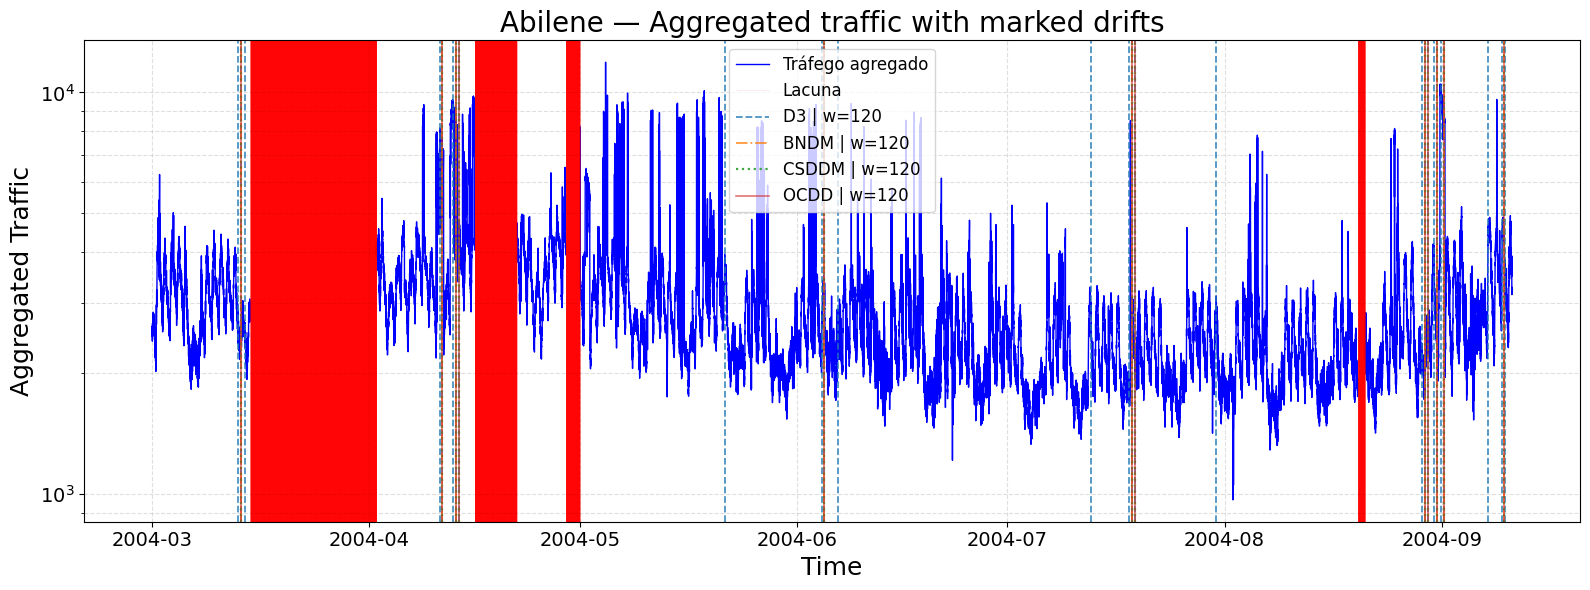

,dataset,detector,window,n_drifts_plotados,modo_seeds
0,Abilene,D3,120,27,union
1,Abilene,BNDM,120,9,union
2,Abilene,CSDDM,120,12,union
3,Abilene,OCDD,120,12,union



Dataset: GÉANT
Tamanho série original: 11460
Tamanho série detector sem NaN: 7026
D3     | window=  60 | drifts plotados=17
BNDM   | window=  60 | drifts plotados=8
CSDDM  | window=  60 | drifts plotados=13
OCDD   | window=  60 | drifts plotados=13
Figura salva em: plots/drifts_marcados/geant_drifts_union.png


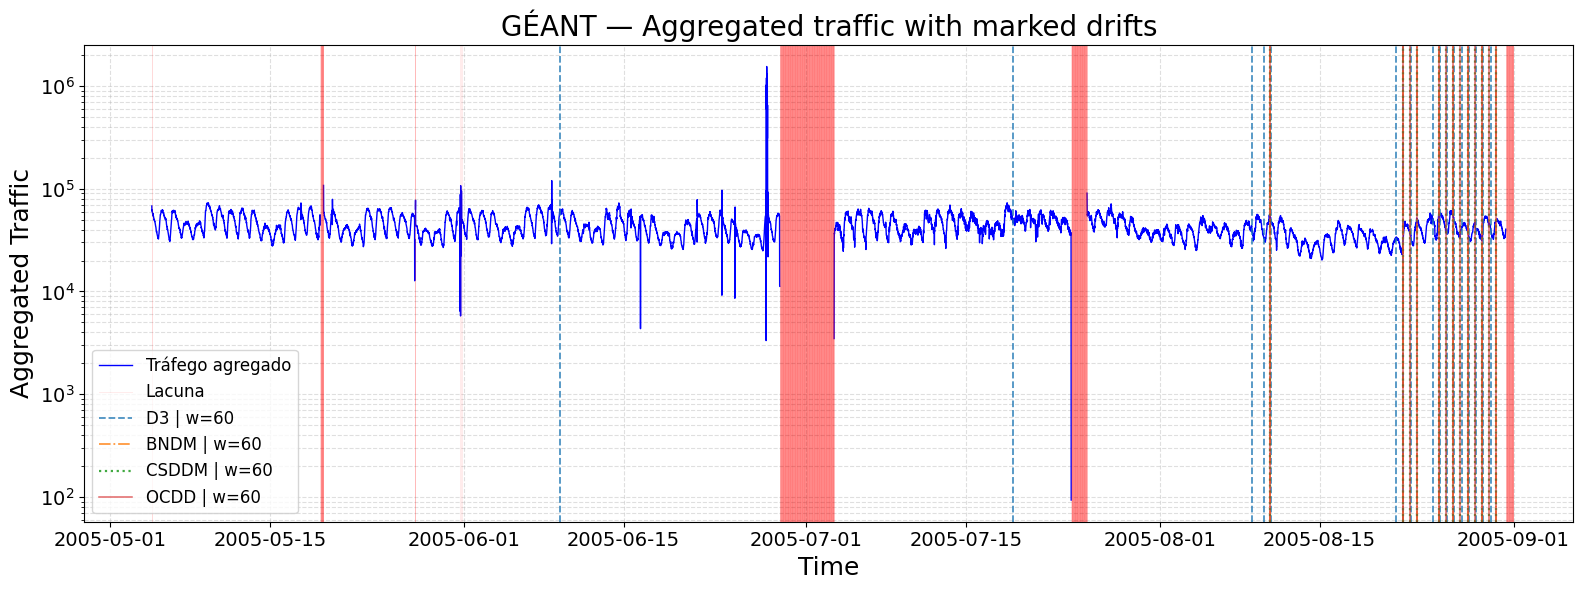

,dataset,detector,window,n_drifts_plotados,modo_seeds
0,GÉANT,D3,60,17,union
1,GÉANT,BNDM,60,8,union
2,GÉANT,CSDDM,60,13,union
3,GÉANT,OCDD,60,13,union


In [5]:
import ast
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# CONFIG
# ============================================================

SUMMARY_FILES = {
    "Abilene": "./results_sem_log//outputs/abilene_diferenca_sazonal_sem_log_com_lacunas/abilene_summary.csv",
    "GÉANT": "./results_sem_log//outputs/geant_diferenca_sazonal_sem_log_com_lacunas/geant_summary.csv",
}

# Use aqui os DataFrames já carregados no notebook.
# Preferencialmente, use os DataFrames ORIGINAIS tratados com lacunas:
# df_abilene e df_geant.
DATASETS_ORIGINAIS = {
    "Abilene": df_abilene,
    "GÉANT": df_geant,
}

# Use aqui as séries/DataFrames que entraram nos detectores.
# Pelo seu caso, provavelmente foram as diferenças sazonais logarítmicas:
# var_abilene e var_geant.
#
# Se os detectores foram rodados no tráfego original, troque para df_abilene/df_geant.
DATASETS_DETECTORES = {
    "Abilene": abilene_variation,
    "GÉANT": geant_variation,
}

WINDOWS_ESCOLHIDAS = {
    "Abilene": {
        "D3": 120,
        "BNDM": 120,
        "CSDDM": 120,
        "OCDD": 120,
    },
    "GÉANT": {
        "D3": 60,
        "BNDM": 60,
        "CSDDM": 60,
        "OCDD": 60,
    },
}

# Como combinar várias seeds:
# "union"        -> apareceu em qualquer seed
# "intersection" -> apareceu em todas as seeds
# "majority"     -> apareceu em pelo menos META_MAJORITY das seeds
# "seed"         -> usa só uma seed específica
MODO_SEEDS = "union"
SEED_ESCOLHIDA = 42
META_MAJORITY = 0.5

# Se True, assume que drift_indices_json se refere à série SEM NaN usada no detector.
# Esse costuma ser o caso quando antes de rodar o detector foi feito dropna().
MAPEAR_INDICES_PELA_SERIE_SEM_NAN = False

OUT_DIR = Path("./plots/drifts_marcados")
OUT_DIR.mkdir(parents=True, exist_ok=True)

SALVAR_FIGURA = True
MOSTRAR_FIGURA = True

# Zoom opcional por posição da série original.
# Use None para mostrar tudo.
X_MIN = None
X_MAX = None

# Exemplo:
# X_MIN = 0
# X_MAX = 500

USAR_ESCALA_LOG = True

STYLES = {
    "D3": {
        "color": "#1f77b4",
        "linestyle": "--",
        "linewidth": 1.3,
        "alpha": 0.8,
    },
    "BNDM": {
        "color": "#ff7f0e",
        "linestyle": "-.",
        "linewidth": 1.3,
        "alpha": 0.8,
    },
    "CSDDM": {
        "color": "#2ca02c",
        "linestyle": ":",
        "linewidth": 1.6,
        "alpha": 0.9,
    },
    "OCDD": {
        "color": "#d62728",
        "linestyle": "-",
        "linewidth": 1.1,
        "alpha": 0.7,
    },
}


# ============================================================
# FUNÇÕES
# ============================================================

def parse_drift_indices(valor):
    if valor is None:
        return []

    if isinstance(valor, float) and np.isnan(valor):
        return []

    if isinstance(valor, list):
        return [int(x) for x in valor]

    if isinstance(valor, str):
        texto = valor.strip()

        if texto == "" or texto.lower() in {"nan", "none", "null"}:
            return []

        try:
            return [int(x) for x in json.loads(texto)]
        except Exception:
            pass

        try:
            return [int(x) for x in ast.literal_eval(texto)]
        except Exception:
            return []

    return []


def agregado_com_lacunas(df):
    """
    Igual à ideia do código antigo:
    - soma colunas numéricas;
    - se a linha inteira é NaN, o agregado também vira NaN.
    """
    df_num = df.select_dtypes(include=[np.number]).copy()

    agregado = df_num.sum(axis=1, skipna=True)

    linhas_lacuna = df_num.isna().all(axis=1)
    agregado[linhas_lacuna] = np.nan

    return agregado


def serie_detector_sem_nan(df_detector):
    """
    Cria a Aggregated serie que provavelmente foi usada pelos detectores:
    soma das colunas numéricas e remove pontos NaN.

    Isso é importante porque drift_indices_json normalmente guarda posições
    da série entregue ao detector, e não necessariamente posições do df original.
    """
    serie = agregado_com_lacunas(df_detector)

    # Remove NaN e também remove valores infinitos, se existirem.
    serie = serie.replace([np.inf, -np.inf], np.nan).dropna()

    return serie


def combinar_drifts_por_seed(sub_df, modo="union", seed_escolhida=None, meta_majority=0.5):
    if sub_df.empty:
        return []

    if modo == "seed":
        if "seed" not in sub_df.columns:
            raise ValueError("MODO_SEEDS='seed', mas o CSV não possui coluna 'seed'.")

        sub_seed = sub_df[sub_df["seed"] == seed_escolhida]

        if sub_seed.empty:
            print(f"⚠️ Seed {seed_escolhida} não encontrada. Usando primeira seed disponível.")
            sub_seed = sub_df.iloc[[0]]

        indices = []
        for valor in sub_seed["drift_indices_json"]:
            indices.extend(parse_drift_indices(valor))

        return sorted(set(indices))

    listas = []

    for valor in sub_df["drift_indices_json"]:
        listas.append(set(parse_drift_indices(valor)))

    if not listas:
        return []

    if modo == "union":
        return sorted(set().union(*listas))

    if modo == "intersection":
        return sorted(set.intersection(*listas))

    if modo == "majority":
        contagem = {}
        total = len(listas)
        minimo = int(np.ceil(meta_majority * total))

        for indices in listas:
            for idx in indices:
                contagem[idx] = contagem.get(idx, 0) + 1

        return sorted([
            idx for idx, qtd in contagem.items()
            if qtd >= minimo
        ])

    raise ValueError("Use MODO_SEEDS como: union, intersection, majority ou seed.")


def aplicar_zoom_por_posicao(serie, x_min=None, x_max=None):
    pos = np.arange(len(serie))
    mask = np.ones(len(serie), dtype=bool)

    if x_min is not None:
        mask &= pos >= x_min

    if x_max is not None:
        mask &= pos <= x_max

    return serie.iloc[mask]


def normalizar_nome_dataset(nome):
    return (
        nome.lower()
        .replace("é", "e")
        .replace("É", "e")
        .replace("á", "a")
        .replace(" ", "_")
    )


# ============================================================
# PLOT
# ============================================================

for dataset_name, summary_path in SUMMARY_FILES.items():

    print("\n" + "=" * 70)
    print(f"Dataset: {dataset_name}")
    print("=" * 70)

    df_summary = pd.read_csv(summary_path)

    df_original = DATASETS_ORIGINAIS[dataset_name]
    df_detector = DATASETS_DETECTORES[dataset_name]

    # Série que será desenhada no gráfico: tráfego agregado original.
    trafego_agregado = agregado_com_lacunas(df_original)

    # Série usada para mapear os índices dos drifts.
    serie_detector = serie_detector_sem_nan(df_detector)

    print(f"Tamanho série original: {len(trafego_agregado)}")
    print(f"Tamanho série detector sem NaN: {len(serie_detector)}")

    trafego_plot = aplicar_zoom_por_posicao(
        trafego_agregado,
        x_min=X_MIN,
        x_max=X_MAX
    )

    fig, ax = plt.subplots(figsize=(16, 6))

    ax.plot(
        trafego_plot.index,
        trafego_plot.values,
        label="Tráfego agregado",
        color="blue",
        linewidth=1.0,
    )

    # Marca lacunas, como no código antigo
    lacunas = df_original.select_dtypes(include=[np.number]).isna().all(axis=1)

    for ts in df_original.index[lacunas]:
        if X_MIN is not None or X_MAX is not None:
            pos_ts = trafego_agregado.index.get_loc(ts)
            if X_MIN is not None and pos_ts < X_MIN:
                continue
            if X_MAX is not None and pos_ts > X_MAX:
                continue

        ax.axvline(
            ts,
            color="red",
            alpha=0.08,
            linewidth=0.7,
            label="Lacuna" if "Lacuna" not in ax.get_legend_handles_labels()[1] else None
        )

    detector_windows = WINDOWS_ESCOLHIDAS[dataset_name]

    resumo = []

    for detector, window in detector_windows.items():

        sub = df_summary[
            (df_summary["detector"] == detector) &
            (df_summary["window"] == window)
        ]

        if sub.empty:
            print(f"⚠️ Sem dados para {detector} | window={window}")
            continue

        drift_indices = combinar_drifts_por_seed(
            sub,
            modo=MODO_SEEDS,
            seed_escolhida=SEED_ESCOLHIDA,
            meta_majority=META_MAJORITY,
        )

        drift_timestamps = []

        for idx in drift_indices:
            idx = int(idx)

            if MAPEAR_INDICES_PELA_SERIE_SEM_NAN:
                # Índice é posição dentro da série sem NaN usada no detector.
                if 0 <= idx < len(serie_detector):
                    ts = serie_detector.index[idx]
                    drift_timestamps.append(ts)
            else:
                # Índice é posição direta no DataFrame original.
                if 0 <= idx < len(trafego_agregado):
                    ts = trafego_agregado.index[idx]
                    drift_timestamps.append(ts)

        # Remove timestamps duplicados
        drift_timestamps = sorted(set(drift_timestamps))

        # Aplica zoom
        if X_MIN is not None or X_MAX is not None:
            inicio = trafego_agregado.index[X_MIN] if X_MIN is not None else trafego_agregado.index.min()
            fim = trafego_agregado.index[X_MAX] if X_MAX is not None else trafego_agregado.index.max()

            drift_timestamps = [
                ts for ts in drift_timestamps
                if inicio <= ts <= fim
            ]

        style = STYLES.get(detector, {})

        label_usado = False

        for ts in drift_timestamps:
            ax.axvline(
                ts,
                label=f"{detector} | w={window}" if not label_usado else None,
                **style
            )
            label_usado = True

        resumo.append({
            "dataset": dataset_name,
            "detector": detector,
            "window": window,
            "n_drifts_plotados": len(drift_timestamps),
            "modo_seeds": MODO_SEEDS,
        })

        print(
            f"{detector:6s} | window={window:4d} | "
            f"drifts plotados={len(drift_timestamps)}"
        )

    titulo = (
        f"{dataset_name} — Aggregated traffic with marked drifts"
    )

    if MAPEAR_INDICES_PELA_SERIE_SEM_NAN:
        titulo += " | indices mapped by the series without NaN"

    ax.set_title(titulo, fontsize=20)
    ax.set_xlabel("Time", fontsize=18)
    ax.set_ylabel("Aggregated Traffic", fontsize=18)

    ax.tick_params(axis="both", labelsize=14)
    # ↑ timestamps do eixo X + valores numéricos do eixo Y

    if USAR_ESCALA_LOG:
        ax.set_yscale("log")

    ax.grid(True, which="both", linestyle="--", alpha=0.4)
    ax.legend(loc="best", fontsize=12)

    plt.tight_layout()

    nome_dataset = normalizar_nome_dataset(dataset_name)

    if X_MIN is not None or X_MAX is not None:
        sufixo_zoom = f"_zoom_{X_MIN}_{X_MAX}"
    else:
        sufixo_zoom = ""

    out_path = OUT_DIR / f"{nome_dataset}_drifts_{MODO_SEEDS}{sufixo_zoom}.png"

    if SALVAR_FIGURA:
        plt.savefig(out_path, dpi=300, bbox_inches="tight")
        print(f"Figura salva em: {out_path}")

    if MOSTRAR_FIGURA:
        plt.show()
    else:
        plt.close(fig)

    display(pd.DataFrame(resumo))

In [6]:
import ast
import json
import numpy as np
import pandas as pd


def parse_drift_indices(valor):
    if valor is None:
        return []

    if isinstance(valor, float) and np.isnan(valor):
        return []

    if isinstance(valor, list):
        return [int(x) for x in valor]

    if isinstance(valor, str):
        texto = valor.strip()

        if texto == "" or texto.lower() in {"nan", "none", "null"}:
            return []

        try:
            return [int(x) for x in json.loads(texto)]
        except Exception:
            pass

        try:
            return [int(x) for x in ast.literal_eval(texto)]
        except Exception:
            return []

    return []


def diagnosticar_indices_drift(
    summary_path,
    df_original,
    df_detector,
    dataset="GÉANT",
    window=60
):
    df_summary = pd.read_csv(summary_path)

    df_num_original = df_original.select_dtypes(include=[np.number])
    trafego_agregado = df_num_original.sum(axis=1, skipna=True)
    trafego_agregado[df_num_original.isna().all(axis=1)] = np.nan

    df_num_detector = df_detector.select_dtypes(include=[np.number])
    serie_detector = df_num_detector.sum(axis=1, skipna=True)
    serie_detector[df_num_detector.isna().all(axis=1)] = np.nan
    serie_detector = serie_detector.replace([np.inf, -np.inf], np.nan).dropna()

    linhas = []

    for detector in sorted(df_summary["detector"].unique()):

        sub = df_summary[
            (df_summary["detector"] == detector) &
            (df_summary["window"] == window)
        ]

        if sub.empty:
            continue

        todos_indices = []

        for _, row in sub.iterrows():
            indices = parse_drift_indices(row["drift_indices_json"])
            todos_indices.extend(indices)

        todos_indices_unicos = sorted(set(todos_indices))

        validos_original = [
            idx for idx in todos_indices_unicos
            if 0 <= idx < len(trafego_agregado)
        ]

        validos_detector_sem_nan = [
            idx for idx in todos_indices_unicos
            if 0 <= idx < len(serie_detector)
        ]

        linhas.append({
            "dataset": dataset,
            "detector": detector,
            "window": window,

            "media_n_drifts_csv": sub["n_drifts"].mean(),
            "min_n_drifts_csv": sub["n_drifts"].min(),
            "max_n_drifts_csv": sub["n_drifts"].max(),
            "n_seeds": len(sub),

            "n_indices_unicos_no_json": len(todos_indices_unicos),

            "tamanho_serie_original": len(trafego_agregado),
            "validos_como_indice_original": len(validos_original),

            "tamanho_serie_detector_sem_nan": len(serie_detector),
            "validos_como_indice_detector_sem_nan": len(validos_detector_sem_nan),

            "menor_indice_json": min(todos_indices_unicos) if todos_indices_unicos else np.nan,
            "maior_indice_json": max(todos_indices_unicos) if todos_indices_unicos else np.nan,
        })

    return pd.DataFrame(linhas)


diagnostico_geant_48 = diagnosticar_indices_drift(
    summary_path="./results_sem_log//outputs/geant_diferenca_sazonal_sem_log_com_lacunas/geant_summary.csv",
    df_original=df_geant,
    df_detector=geant_variation,
    dataset="GÉANT",
    window=48
)

display(diagnostico_geant_48)

,dataset,detector,window,media_n_drifts_csv,min_n_drifts_csv,max_n_drifts_csv,n_seeds,n_indices_unicos_no_json,tamanho_serie_original,validos_como_indice_original,tamanho_serie_detector_sem_nan,validos_como_indice_detector_sem_nan,menor_indice_json,maior_indice_json
0,GÉANT,BNDM,48,10.0,10,10,1,10,11460,10,7026,0,9288,11289
1,GÉANT,CSDDM,48,18.0,18,18,5,18,11460,18,7026,0,9288,11289
2,GÉANT,D3,48,23.0,23,23,5,23,11460,23,7026,1,3423,11383
3,GÉANT,OCDD,48,18.0,18,18,1,18,11460,18,7026,0,9288,11289


In [7]:
import ast
import json
from pathlib import Path

import numpy as np
import pandas as pd


# ============================================================
# CONFIG
# ============================================================

SUMMARY_FILES = {
    "Abilene": "./results_sem_log//outputs/abilene_diferenca_sazonal_sem_log_com_lacunas/abilene_summary.csv",
    "GÉANT": "./results_sem_log//outputs/geant_diferenca_sazonal_sem_log_com_lacunas/geant_summary.csv",
}

# DataFrames originais tratados com lacunas
DATASETS_ORIGINAIS = {
    "Abilene": df_abilene,
    "GÉANT": df_geant,
}

# Séries/DataFrames usados pelos detectores
# Se os detectores foram rodados na diferença sazonal logarítmica, mantenha assim.
DATASETS_DETECTORES = {
    "Abilene": abilene_variation,
    "GÉANT": geant_variation,
}

WINDOWS_ESCOLHIDAS = {
    "Abilene": {
        "D3": 120,
        "BNDM": 120,
        "CSDDM": 120,
        "OCDD": 120,
    },
    "GÉANT": {
        "D3": 60,
        "BNDM": 60,
        "CSDDM": 60,
        "OCDD": 60,
    },
}

# Como combinar várias seeds:
# "union"        -> apareceu em qualquer seed
# "intersection" -> apareceu em todas as seeds
# "majority"     -> apareceu em pelo menos META_MAJORITY das seeds
# "seed"         -> usa só uma seed específica
MODO_SEEDS = "union"
SEED_ESCOLHIDA = 42
META_MAJORITY = 0.5

# Se True, assume que drift_indices_json se refere à série SEM NaN usada no detector.
MAPEAR_INDICES_PELA_SERIE_SEM_NAN = False

OUT_DIR = Path("./outputs/drifts_tabelas")
OUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# FUNÇÕES AUXILIARES
# ============================================================

def parse_drift_indices(valor):
    if valor is None:
        return []

    if isinstance(valor, float) and np.isnan(valor):
        return []

    if isinstance(valor, list):
        return [int(x) for x in valor]

    if isinstance(valor, str):
        texto = valor.strip()

        if texto == "" or texto.lower() in {"nan", "none", "null"}:
            return []

        try:
            return [int(x) for x in json.loads(texto)]
        except Exception:
            pass

        try:
            return [int(x) for x in ast.literal_eval(texto)]
        except Exception:
            return []

    return []


def agregado_com_lacunas(df):
    """
    Soma as colunas numéricas.
    Se a linha inteira for NaN, o agregado também vira NaN.
    """
    df_num = df.select_dtypes(include=[np.number]).copy()

    agregado = df_num.sum(axis=1, skipna=True)

    linhas_lacuna = df_num.isna().all(axis=1)
    agregado[linhas_lacuna] = np.nan

    return agregado


def serie_detector_sem_nan(df_detector):
    """
    Aggregated serie provavelmente usada pelo detector:
    soma colunas numéricas, remove NaN e infinitos.
    """
    serie = agregado_com_lacunas(df_detector)
    serie = serie.replace([np.inf, -np.inf], np.nan).dropna()
    return serie


def combinar_drifts_por_seed(sub_df, modo="union", seed_escolhida=None, meta_majority=0.5):
    if sub_df.empty:
        return []

    if modo == "seed":
        if "seed" not in sub_df.columns:
            raise ValueError("MODO_SEEDS='seed', mas o CSV não possui coluna 'seed'.")

        sub_seed = sub_df[sub_df["seed"] == seed_escolhida]

        if sub_seed.empty:
            print(f"⚠️ Seed {seed_escolhida} não encontrada. Usando primeira seed disponível.")
            sub_seed = sub_df.iloc[[0]]

        indices = []
        for valor in sub_seed["drift_indices_json"]:
            indices.extend(parse_drift_indices(valor))

        return sorted(set(indices))

    listas = []

    for valor in sub_df["drift_indices_json"]:
        listas.append(set(parse_drift_indices(valor)))

    if not listas:
        return []

    if modo == "union":
        return sorted(set().union(*listas))

    if modo == "intersection":
        return sorted(set.intersection(*listas))

    if modo == "majority":
        contagem = {}
        total = len(listas)
        minimo = int(np.ceil(meta_majority * total))

        for indices in listas:
            for idx in indices:
                contagem[idx] = contagem.get(idx, 0) + 1

        return sorted([
            idx for idx, qtd in contagem.items()
            if qtd >= minimo
        ])

    raise ValueError("Use MODO_SEEDS como: union, intersection, majority ou seed.")


def obter_seeds_que_detectaram(sub_df, indice_drift):
    """
    Para cada drift, informa em quais seeds ele apareceu.
    """
    if "seed" not in sub_df.columns:
        return None

    seeds = []

    for _, row in sub_df.iterrows():
        indices = set(parse_drift_indices(row["drift_indices_json"]))

        if indice_drift in indices:
            seeds.append(row["seed"])

    return sorted(seeds)


def posicao_original_do_timestamp(index_original, ts):
    """
    Retorna a posição inteira do timestamp na série original.
    """
    try:
        return int(index_original.get_loc(ts))
    except Exception:
        return None


# ============================================================
# GERAÇÃO DAS TABELAS
# ============================================================

linhas_detalhadas = []
linhas_resumo = []

for dataset_name, summary_path in SUMMARY_FILES.items():

    print("\n" + "=" * 70)
    print(f"Dataset: {dataset_name}")
    print("=" * 70)

    df_summary = pd.read_csv(summary_path)

    df_original = DATASETS_ORIGINAIS[dataset_name]
    df_detector = DATASETS_DETECTORES[dataset_name]

    trafego_agregado = agregado_com_lacunas(df_original)
    serie_detector = serie_detector_sem_nan(df_detector)

    detector_windows = WINDOWS_ESCOLHIDAS[dataset_name]

    for detector, window in detector_windows.items():

        sub = df_summary[
            (df_summary["detector"] == detector) &
            (df_summary["window"] == window)
        ]

        if sub.empty:
            print(f"⚠️ Sem dados para {dataset_name} | {detector} | window={window}")
            continue

        drift_indices = combinar_drifts_por_seed(
            sub,
            modo=MODO_SEEDS,
            seed_escolhida=SEED_ESCOLHIDA,
            meta_majority=META_MAJORITY,
        )

        registros_detector = []

        for drift_idx_detector in drift_indices:
            drift_idx_detector = int(drift_idx_detector)

            if MAPEAR_INDICES_PELA_SERIE_SEM_NAN:
                if not (0 <= drift_idx_detector < len(serie_detector)):
                    continue

                timestamp = serie_detector.index[drift_idx_detector]

            else:
                if not (0 <= drift_idx_detector < len(trafego_agregado)):
                    continue

                timestamp = trafego_agregado.index[drift_idx_detector]

            idx_original = posicao_original_do_timestamp(
                trafego_agregado.index,
                timestamp
            )

            valor_trafego_agregado = (
                trafego_agregado.loc[timestamp]
                if timestamp in trafego_agregado.index
                else np.nan
            )

            valor_detector_agregado = (
                serie_detector.loc[timestamp]
                if timestamp in serie_detector.index
                else np.nan
            )

            seeds_detectaram = obter_seeds_que_detectaram(
                sub,
                drift_idx_detector
            )

            if seeds_detectaram is None:
                n_seeds_detectaram = np.nan
                seeds_detectaram_txt = ""
            else:
                n_seeds_detectaram = len(seeds_detectaram)
                seeds_detectaram_txt = ",".join(map(str, seeds_detectaram))

            registros_detector.append({
                "dataset": dataset_name,
                "detector": detector,
                "window": window,
                "modo_seeds": MODO_SEEDS,

                # posição do drift na série usada pelo detector
                "drift_index_detector": drift_idx_detector,

                # timestamp correspondente
                "timestamp": timestamp,

                # posição equivalente no dataframe original
                "drift_index_original": idx_original,

                # valor do tráfego agregado original naquele timestamp
                "trafego_agregado_original": valor_trafego_agregado,

                # valor da Aggregated serie usada no detector naquele timestamp
                "valor_agregado_detector": valor_detector_agregado,

                # seeds em que o drift apareceu
                "n_seeds_detectaram": n_seeds_detectaram,
                "seeds_detectaram": seeds_detectaram_txt,
            })

        linhas_detalhadas.extend(registros_detector)

        linhas_resumo.append({
            "dataset": dataset_name,
            "detector": detector,
            "window": window,
            "modo_seeds": MODO_SEEDS,
            "n_drifts_localizados": len(registros_detector),
            "primeiro_drift": registros_detector[0]["timestamp"] if registros_detector else pd.NaT,
            "ultimo_drift": registros_detector[-1]["timestamp"] if registros_detector else pd.NaT,
        })

        print(
            f"{dataset_name:7s} | {detector:6s} | "
            f"window={window:4d} | drifts localizados={len(registros_detector)}"
        )


df_drifts_detalhado = pd.DataFrame(linhas_detalhadas)
df_drifts_resumo = pd.DataFrame(linhas_resumo)

if not df_drifts_detalhado.empty:
    df_drifts_detalhado = df_drifts_detalhado.sort_values(
        ["dataset", "detector", "window", "timestamp"]
    ).reset_index(drop=True)

if not df_drifts_resumo.empty:
    df_drifts_resumo = df_drifts_resumo.sort_values(
        ["dataset", "detector", "window"]
    ).reset_index(drop=True)

# Salva os CSVs
path_detalhado = OUT_DIR / "drifts_detalhados.csv"
path_resumo = OUT_DIR / "drifts_resumo.csv"

df_drifts_detalhado.to_csv(path_detalhado, index=False)
df_drifts_resumo.to_csv(path_resumo, index=False)

print("\nArquivos salvos:")
print(path_detalhado)
print(path_resumo)

print("\nResumo:")
display(df_drifts_resumo)

print("\nTabela detalhada:")
display(df_drifts_detalhado)


Dataset: Abilene
Abilene | D3     | window= 120 | drifts localizados=27
Abilene | BNDM   | window= 120 | drifts localizados=9
Abilene | CSDDM  | window= 120 | drifts localizados=12
Abilene | OCDD   | window= 120 | drifts localizados=12

Dataset: GÉANT
GÉANT   | D3     | window=  60 | drifts localizados=17
GÉANT   | BNDM   | window=  60 | drifts localizados=8
GÉANT   | CSDDM  | window=  60 | drifts localizados=13
GÉANT   | OCDD   | window=  60 | drifts localizados=13

Arquivos salvos:
outputs/drifts_tabelas/drifts_detalhados.csv
outputs/drifts_tabelas/drifts_resumo.csv

Resumo:


,dataset,detector,window,modo_seeds,n_drifts_localizados,primeiro_drift,ultimo_drift
0,Abilene,BNDM,120,union,9,2004-03-13 15:35:00,2004-09-09 21:10:00
1,Abilene,CSDDM,120,union,12,2004-03-13 15:35:00,2004-09-09 21:10:00
2,Abilene,D3,120,union,27,2004-03-13 06:40:00,2004-09-09 22:20:00
3,Abilene,OCDD,120,union,12,2004-03-13 15:35:00,2004-09-09 21:10:00
4,GÉANT,BNDM,60,union,8,2005-08-10 15:30:00,2005-08-30 11:15:00
5,GÉANT,CSDDM,60,union,13,2005-08-10 15:30:00,2005-08-30 11:15:00
6,GÉANT,D3,60,union,17,2005-06-09 10:15:00,2005-08-30 00:00:00
7,GÉANT,OCDD,60,union,13,2005-08-10 15:30:00,2005-08-30 11:15:00



Tabela detalhada:


,dataset,detector,window,modo_seeds,drift_index_detector,timestamp,drift_index_original,trafego_agregado_original,valor_agregado_detector,n_seeds_detectaram,seeds_detectaram
0,Abilene,BNDM,120,union,3643,2004-03-13 15:35:00,3643,2538.649138,509.042976,1,-1
1,Abilene,BNDM,120,union,11916,2004-04-11 09:00:00,11916,7520.464408,4704.626098,1,-1
2,Abilene,BNDM,120,union,12484,2004-04-13 08:20:00,12484,8611.559385,5908.451112,1,-1
3,Abilene,BNDM,120,union,27610,2004-06-04 20:50:00,27610,3246.842799,1183.649643,1,-1
4,Abilene,BNDM,120,union,40260,2004-07-18 19:00:00,40260,3023.187452,1270.105493,1,-1
...,...,...,...,...,...,...,...,...,...,...,...
106,GÉANT,OCDD,60,union,11073,2005-08-27 23:15:00,11073,39370.281547,10248.825035,1,-1
107,GÉANT,OCDD,60,union,11133,2005-08-28 14:15:00,11133,45807.631982,14762.261100,1,-1
108,GÉANT,OCDD,60,union,11193,2005-08-29 05:15:00,11193,31437.194509,8033.504852,1,-1
109,GÉANT,OCDD,60,union,11253,2005-08-29 20:15:00,11253,45767.152895,5791.934075,1,-1


```text
Comparação sem log
======================================================================
Dataset: Abilene
======================================================================
Abilene | D3     | window= 120 | drifts localizados=27
Abilene | BNDM   | window= 120 | drifts localizados=9
Abilene | CSDDM  | window= 120 | drifts localizados=12
Abilene | OCDD   | window= 120 | drifts localizados=12

======================================================================
Dataset: GÉANT
======================================================================
GÉANT   | D3     | window=  48 | drifts localizados=23
GÉANT   | BNDM   | window=  48 | drifts localizados=10
GÉANT   | CSDDM  | window=  48 | drifts localizados=18
GÉANT   | OCDD   | window=  48 | drifts localizados=18
```

```text
comparando com log
======================================================================
Dataset: Abilene
======================================================================
D3     | window= 120 | drifts plotados=16
BNDM   | window= 120 | drifts plotados=7
CSDDM  | window= 120 | drifts plotados=11
OCDD   | window= 120 | drifts plotados=11
======================================================================
Dataset: GÉANT
======================================================================
D3     | window=  48 | drifts plotados=4
BNDM   | window=  48 | drifts plotados=1
CSDDM  | window=  48 | drifts plotados=1
OCDD   | window=  48 | drifts plotados=1
```

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd


# ============================================================
# CONFIG
# ============================================================

# Margem de segurança em número de amostras.
# Exemplo: MARGEM_AMOSTRAS = 5 significa que drifts separados
# por até 5 posições ainda são considerados parte do mesmo evento.
MARGEM_AMOSTRAS = 20

# Quantos detectores diferentes precisam aparecer no intervalo
# para considerar que houve consenso.
MIN_DETECTORES_CONCORDANDO = 2

# Se quiser ser mais rigoroso, use 3.
# MIN_DETECTORES_CONCORDANDO = 3

OUT_DIR = Path("./outputs/drifts_tabelas")
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_CONSENSO = OUT_DIR / "drifts_consenso_detectores.csv"


# ============================================================
# FUNÇÕES
# ============================================================

def criar_intervalos_consenso(
    df_drifts,
    margem_amostras=5,
    min_detectores=2,
):
    """
    Agrupa drifts próximos em intervalos de consenso.

    A lógica é:
    - ordena os drifts por dataset e posição original;
    - drifts separados por até margem_amostras entram no mesmo grupo;
    - mantém apenas grupos com pelo menos min_detectores detectores diferentes.
    """

    if df_drifts.empty:
        return pd.DataFrame()

    colunas_necessarias = {
        "dataset",
        "detector",
        "window",
        "timestamp",
        "drift_index_original",
        "drift_index_detector",
    }

    faltando = colunas_necessarias - set(df_drifts.columns)

    if faltando:
        raise ValueError(f"Faltam colunas no df_drifts_detalhado: {faltando}")

    df = df_drifts.copy()

    df = df.dropna(subset=["drift_index_original"])
    df["drift_index_original"] = df["drift_index_original"].astype(int)
    df["timestamp"] = pd.to_datetime(df["timestamp"])

    linhas_consenso = []

    for dataset_name, df_dataset in df.groupby("dataset"):

        df_dataset = df_dataset.sort_values("drift_index_original").reset_index(drop=True)

        grupo_atual = []
        ultimo_idx = None
        id_evento = 0

        for _, row in df_dataset.iterrows():

            idx = int(row["drift_index_original"])

            if ultimo_idx is None:
                grupo_atual = [row]
                ultimo_idx = idx
                continue

            distancia = idx - ultimo_idx

            if distancia <= margem_amostras:
                grupo_atual.append(row)
            else:
                id_evento += 1
                linha = resumir_grupo_consenso(
                    grupo_atual,
                    dataset_name,
                    id_evento,
                    min_detectores,
                )

                if linha is not None:
                    linhas_consenso.append(linha)

                grupo_atual = [row]

            ultimo_idx = idx

        if grupo_atual:
            id_evento += 1
            linha = resumir_grupo_consenso(
                grupo_atual,
                dataset_name,
                id_evento,
                min_detectores,
            )

            if linha is not None:
                linhas_consenso.append(linha)

    return pd.DataFrame(linhas_consenso)


def resumir_grupo_consenso(
    grupo,
    dataset_name,
    id_evento,
    min_detectores,
):
    """
    Resume um grupo de drifts próximos.
    """

    df_grupo = pd.DataFrame(grupo)

    detectores = sorted(df_grupo["detector"].unique())
    n_detectores = len(detectores)

    if n_detectores < min_detectores:
        return None

    inicio_idx = int(df_grupo["drift_index_original"].min())
    fim_idx = int(df_grupo["drift_index_original"].max())

    inicio_ts = df_grupo.loc[
        df_grupo["drift_index_original"].idxmin(),
        "timestamp"
    ]

    fim_ts = df_grupo.loc[
        df_grupo["drift_index_original"].idxmax(),
        "timestamp"
    ]

    centro_idx = int(round(df_grupo["drift_index_original"].median()))

    centro_ts = df_grupo.iloc[
        (df_grupo["drift_index_original"] - centro_idx).abs().argsort().iloc[0]
    ]["timestamp"]

    windows_por_detector = (
        df_grupo
        .groupby("detector")["window"]
        .apply(lambda x: ",".join(map(str, sorted(set(x)))))
        .to_dict()
    )

    indices_por_detector = (
        df_grupo
        .groupby("detector")["drift_index_original"]
        .apply(lambda x: ",".join(map(str, sorted(set(map(int, x))))))
        .to_dict()
    )

    timestamps_por_detector = (
        df_grupo
        .groupby("detector")["timestamp"]
        .apply(lambda x: " | ".join(str(v) for v in sorted(set(x))))
        .to_dict()
    )

    return {
        "dataset": dataset_name,
        "evento_consenso": id_evento,

        "inicio_timestamp": inicio_ts,
        "fim_timestamp": fim_ts,
        "centro_timestamp_aproximado": centro_ts,

        "inicio_indice_original": inicio_idx,
        "fim_indice_original": fim_idx,
        "centro_indice_aproximado": centro_idx,

        "largura_intervalo_amostras": fim_idx - inicio_idx + 1,

        "n_detectores_concordando": n_detectores,
        "detectores_concordando": ", ".join(detectores),

        "windows_por_detector": str(windows_por_detector),
        "indices_por_detector": str(indices_por_detector),
        "timestamps_por_detector": str(timestamps_por_detector),

        "n_marcacoes_no_intervalo": len(df_grupo),
    }


# ============================================================
# EXECUÇÃO
# ============================================================

df_consenso = criar_intervalos_consenso(
    df_drifts=df_drifts_detalhado,
    margem_amostras=MARGEM_AMOSTRAS,
    min_detectores=MIN_DETECTORES_CONCORDANDO,
)

if not df_consenso.empty:
    df_consenso = df_consenso.sort_values(
        ["dataset", "inicio_indice_original"]
    ).reset_index(drop=True)

df_consenso.to_csv(OUT_CONSENSO, index=False)

print(f"Arquivo salvo em: {OUT_CONSENSO}")

print("\nEventos de consenso entre detectores:")
display(df_consenso)

Arquivo salvo em: outputs/drifts_tabelas/drifts_consenso_detectores.csv

Eventos de consenso entre detectores:


,dataset,evento_consenso,inicio_timestamp,fim_timestamp,centro_timestamp_aproximado,inicio_indice_original,fim_indice_original,centro_indice_aproximado,largura_intervalo_amostras,n_detectores_concordando,detectores_concordando,windows_por_detector,indices_por_detector,timestamps_por_detector,n_marcacoes_no_intervalo
0,Abilene,2,2004-03-13 15:35:00,2004-03-13 16:45:00,2004-03-13 15:35:00,3643,3657,3643,15,4,"BNDM, CSDDM, D3, OCDD","{'BNDM': '120', 'CSDDM': '120', 'D3': '120', '...","{'BNDM': '3643', 'CSDDM': '3643', 'D3': '3657'...","{'BNDM': '2004-03-13 15:35:00', 'CSDDM': '2004...",4
1,Abilene,5,2004-04-11 09:00:00,2004-04-11 10:10:00,2004-04-11 09:00:00,11916,11930,11916,15,4,"BNDM, CSDDM, D3, OCDD","{'BNDM': '120', 'CSDDM': '120', 'D3': '120', '...","{'BNDM': '11916', 'CSDDM': '11916', 'D3': '119...","{'BNDM': '2004-04-11 09:00:00', 'CSDDM': '2004...",4
2,Abilene,7,2004-04-13 08:20:00,2004-04-13 09:30:00,2004-04-13 08:20:00,12484,12498,12484,15,4,"BNDM, CSDDM, D3, OCDD","{'BNDM': '120', 'CSDDM': '120', 'D3': '120', '...","{'BNDM': '12484', 'CSDDM': '12484', 'D3': '124...","{'BNDM': '2004-04-13 08:20:00', 'CSDDM': '2004...",4
3,Abilene,8,2004-04-13 18:20:00,2004-04-13 19:35:00,2004-04-13 18:20:00,12604,12619,12604,16,3,"CSDDM, D3, OCDD","{'CSDDM': '120', 'D3': '120', 'OCDD': '120'}","{'CSDDM': '12604', 'D3': '12619', 'OCDD': '126...","{'CSDDM': '2004-04-13 18:20:00', 'D3': '2004-0...",3
4,Abilene,11,2004-06-04 20:50:00,2004-06-04 22:00:00,2004-06-04 20:50:00,27610,27624,27610,15,4,"BNDM, CSDDM, D3, OCDD","{'BNDM': '120', 'CSDDM': '120', 'D3': '120', '...","{'BNDM': '27610', 'CSDDM': '27610', 'D3': '276...","{'BNDM': '2004-06-04 20:50:00', 'CSDDM': '2004...",4
5,Abilene,15,2004-07-18 19:00:00,2004-07-18 20:10:00,2004-07-18 19:00:00,40260,40274,40260,15,4,"BNDM, CSDDM, D3, OCDD","{'BNDM': '120', 'CSDDM': '120', 'D3': '120', '...","{'BNDM': '40260', 'CSDDM': '40260', 'D3': '402...","{'BNDM': '2004-07-18 19:00:00', 'CSDDM': '2004...",4
6,Abilene,16,2004-07-19 05:00:00,2004-07-19 06:15:00,2004-07-19 05:00:00,40380,40395,40380,16,3,"CSDDM, D3, OCDD","{'CSDDM': '120', 'D3': '120', 'OCDD': '120'}","{'CSDDM': '40380', 'D3': '40395', 'OCDD': '403...","{'CSDDM': '2004-07-19 05:00:00', 'D3': '2004-0...",3
7,Abilene,19,2004-08-29 14:00:00,2004-08-29 15:10:00,2004-08-29 14:00:00,52296,52310,52296,15,4,"BNDM, CSDDM, D3, OCDD","{'BNDM': '120', 'CSDDM': '120', 'D3': '120', '...","{'BNDM': '52296', 'CSDDM': '52296', 'D3': '523...","{'BNDM': '2004-08-29 14:00:00', 'CSDDM': '2004...",4
8,Abilene,20,2004-08-30 00:00:00,2004-08-30 01:15:00,2004-08-30 00:00:00,52416,52431,52416,16,3,"CSDDM, D3, OCDD","{'CSDDM': '120', 'D3': '120', 'OCDD': '120'}","{'CSDDM': '52416', 'D3': '52431', 'OCDD': '524...","{'CSDDM': '2004-08-30 00:00:00', 'D3': '2004-0...",3
9,Abilene,22,2004-08-31 05:40:00,2004-08-31 06:50:00,2004-08-31 05:40:00,52772,52786,52772,15,4,"BNDM, CSDDM, D3, OCDD","{'BNDM': '120', 'CSDDM': '120', 'D3': '120', '...","{'BNDM': '52772', 'CSDDM': '52772', 'D3': '527...","{'BNDM': '2004-08-31 05:40:00', 'CSDDM': '2004...",4


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# CONFIG
# ============================================================

DATASETS_ORIGINAIS = {
    "Abilene": df_abilene,
    "GÉANT": df_geant,
}

DATASETS_DETECTORES = {
    "Abilene": abilene_variation,
    "GÉANT": geant_variation,
}

# "detector" -> usa os dados que entraram nos detectores
# "original" -> usa o tráfego original
MODO_SERIE = "original"

# Tamanho da região antes/depois:
# tamanho = FATOR_JANELA * window
FATOR_JANELA = 3

# Normalizar cada fluxo antes de concatenar
NORMALIZAR_POR_FLUXO = False

# Transformação para visualização da CCDF
# Para série diferenciada, use "abs" ou "asinh_abs"
# "abs"      -> CCDF da magnitude absoluta dos desvios
# "asinh_abs" -> CCDF da asinh(abs(valor)), reduzindo efeito de extremos
TRANSFORMACAO_CCDF = "nenhuma"  # 

# Salvar também gráfico da série temporal ao redor do drift?
SALVAR_SERIE_TEMPORAL = True

# Salvar CCDF antes/depois?
SALVAR_CCDF = True

# Pasta principal NOVA
OUT_DIR = Path("./plots/ccdf_fluxos_concatenados_ao_redor_dos_drifts")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Se quiser limitar para evitar milhares de imagens, use um número.
# Exemplo: MAX_DRIFTS_POR_CONFIG = 20
# Para salvar todos, deixe None.
MAX_DRIFTS_POR_CONFIG = None

# Se quiser salvar apenas alguns datasets/detectores, edite aqui.
# Use None para todos.
DATASETS_FILTRAR = None
DETECTORES_FILTRAR = None

# Exemplos:
# DATASETS_FILTRAR = ["GÉANT"]
# DETECTORES_FILTRAR = ["D3", "OCDD"]


# ============================================================
# FUNÇÕES
# ============================================================

def nome_seguro(texto):
    texto = str(texto)
    texto = texto.replace("GÉANT", "GEANT")
    texto = texto.replace("É", "E").replace("é", "e")
    texto = texto.replace("Á", "A").replace("á", "a")
    texto = texto.replace(" ", "_")
    texto = texto.replace("/", "_")
    texto = texto.replace("\\", "_")
    texto = texto.replace(":", "-")
    return texto


def obter_df_para_analise(dataset_name, modo_serie="detector"):
    """
    Retorna o DataFrame base a ser usado:
    - original
    - detector
    """
    if modo_serie == "original":
        df = DATASETS_ORIGINAIS[dataset_name].copy()
    elif modo_serie == "detector":
        df = DATASETS_DETECTORES[dataset_name].copy()
    else:
        raise ValueError("MODO_SERIE deve ser 'original' ou 'detector'.")

    df = df.replace([np.inf, -np.inf], np.nan)
    return df


def agregado_com_lacunas(df):
    """
    Série agregada para o gráfico temporal.
    Soma todas as colunas numéricas.
    Se uma linha inteira for NaN, o agregado também vira NaN.
    """
    df_num = df.select_dtypes(include=[np.number]).copy()

    agregado = df_num.sum(axis=1, skipna=True)

    linhas_lacuna = df_num.isna().all(axis=1)
    agregado[linhas_lacuna] = np.nan

    return agregado


def extrair_janelas_antes_depois_concat_fluxos(
    df_base,
    timestamp_drift,
    window,
    fator_janela=3,
    normalizar_por_fluxo=True,
):
    """
    Extrai:

    1) Para CCDF:
       - concatenação de TODOS os fluxos do intervalo antes
       - concatenação de TODOS os fluxos do intervalo depois

    2) Para gráfico temporal:
       - trecho da série agregada ao redor do drift

    Se normalizar_por_fluxo=True:
       cada fluxo é padronizado usando média e desvio calculados
       no intervalo completo antes+depois.
    """

    df_base = df_base.copy()
    df_num = df_base.select_dtypes(include=[np.number]).copy()
    df_num = df_num.replace([np.inf, -np.inf], np.nan)

    timestamp_drift = pd.to_datetime(timestamp_drift)

    if timestamp_drift not in df_num.index:
        return None, None, None, None, None, None, None

    pos = df_num.index.get_loc(timestamp_drift)
    tamanho = int(fator_janela * window)

    ini_antes = max(0, pos - tamanho)
    fim_antes = pos

    ini_depois = pos + 1
    fim_depois = min(len(df_num), pos + 1 + tamanho)

    df_antes = df_num.iloc[ini_antes:fim_antes].copy()
    df_depois = df_num.iloc[ini_depois:fim_depois].copy()

    if normalizar_por_fluxo:
        df_total = pd.concat([df_antes, df_depois], axis=0)

        medias = df_total.mean(axis=0, skipna=True)
        desvios = df_total.std(axis=0, skipna=True)

        desvios = desvios.replace(0, np.nan)

        df_antes_usado = (df_antes - medias) / desvios
        df_depois_usado = (df_depois - medias) / desvios

    else:
        df_antes_usado = df_antes
        df_depois_usado = df_depois

    # Concatena todos os fluxos
    antes = df_antes_usado.to_numpy().reshape(-1)
    depois = df_depois_usado.to_numpy().reshape(-1)

    antes = antes[np.isfinite(antes)]
    depois = depois[np.isfinite(depois)]

    # Série agregada para gráfico temporal
    serie_agregada = agregado_com_lacunas(df_num)

    ini_trecho = max(0, pos - tamanho)
    fim_trecho = min(len(serie_agregada), pos + tamanho + 1)
    trecho = serie_agregada.iloc[ini_trecho:fim_trecho]

    return antes, depois, trecho, pos, tamanho, df_antes.shape, df_depois.shape


def preparar_valores_ccdf(valores, transformacao="abs"):
    """
    Prepara os valores usados na CCDF.

    Para série diferenciada, normalmente faz sentido olhar a magnitude
    dos desvios, por isso usamos abs(valor).
    """
    valores = valores[np.isfinite(valores)]

    if transformacao == "abs":
        valores = np.abs(valores)

    elif transformacao == "asinh_abs":
        valores = np.arcsinh(np.abs(valores))

    elif transformacao == "positivo":
        valores = valores[valores > 0]

    elif transformacao == "nenhuma":
        pass

    else:
        raise ValueError(
            "TRANSFORMACAO_CCDF deve ser 'abs', 'asinh_abs', 'positivo' ou 'nenhuma'."
        )

    valores = valores[np.isfinite(valores)]
    valores = valores[valores >= 0]

    return valores


def calcular_ccdf(valores):
    """
    Calcula CCDF empírica: P(X > x).

    Retorna:
        x ordenado
        ccdf
    """
    valores = np.asarray(valores)
    valores = valores[np.isfinite(valores)]

    if len(valores) == 0:
        return np.array([]), np.array([])

    valores = np.sort(valores)

    n = len(valores)
    ccdf = 1.0 - (np.arange(1, n + 1) / n)

    # Remove pontos com CCDF zero para poder usar escala log
    mask = ccdf > 0

    return valores[mask], ccdf[mask]


def salvar_figura_ccdf_concat_fluxos(
    antes,
    depois,
    dataset,
    detector,
    window,
    timestamp_drift,
    drift_numero,
    tamanho,
    shape_antes,
    shape_depois,
    out_path,
):
    """
    Salva figura com CCDF antes/depois usando todos os fluxos concatenados.
    """

    antes_ccdf_valores = preparar_valores_ccdf(
        antes,
        transformacao=TRANSFORMACAO_CCDF
    )

    depois_ccdf_valores = preparar_valores_ccdf(
        depois,
        transformacao=TRANSFORMACAO_CCDF
    )

    x_antes, y_antes = calcular_ccdf(antes_ccdf_valores)
    x_depois, y_depois = calcular_ccdf(depois_ccdf_valores)

    if len(x_antes) == 0 or len(x_depois) == 0:
        return False

    fig, ax = plt.subplots(figsize=(8, 6))

    ax.plot(
        x_antes,
        y_antes,
        linewidth=2,
        label=f"Before"
        # label=f"Before ({len(antes_ccdf_valores)} values)"
    )

    ax.plot(
        x_depois,
        y_depois,
        linewidth=2,
        label=f"After ({len(depois_ccdf_valores)} values)"
        # label=f"After ({len(depois_ccdf_valores)} values)"
    )

    ax.set_yscale("log")

    # Só usa x log quando os valores são estritamente positivos.
    # Para abs/asinh_abs, normalmente sim.
    if TRANSFORMACAO_CCDF in {"abs", "asinh_abs", "positivo"}:
        x_min_total = min(np.min(x_antes), np.min(x_depois))
        x_max_total = max(np.max(x_antes), np.max(x_depois))

        if x_min_total > 0 and x_max_total > x_min_total:
            ax.set_xscale("log")

    ax.set_title(
        f"{dataset} | Timestamp: {timestamp_drift}", fontsize=20
    )

    if TRANSFORMACAO_CCDF == "abs":
        xlabel = "|value normalized|" if NORMALIZAR_POR_FLUXO else "|value|"
    elif TRANSFORMACAO_CCDF == "asinh_abs":
        xlabel = "asinh(|value normalized|)" if NORMALIZAR_POR_FLUXO else "asinh(|value|)"
    elif TRANSFORMACAO_CCDF == "positivo":
        xlabel = "positive value"
    else:
        xlabel = "Traffic rate (Mbps)"

    ax.set_xlabel(xlabel, fontsize=18)
    ax.set_ylabel("CCDF: P(X > x)", fontsize=18)

    # tamanho dos valores dos eixos X e Y
    ax.tick_params(axis="both", labelsize=12)
    

    ax.grid(True, which="both", linestyle="--", alpha=0.35)

    # legenda
    ax.legend(fontsize=12)

    texto_info = (
        f"Before: {shape_antes[0]} timestamps × {shape_antes[1]} flows\n"
        f"After: {shape_depois[0]} timestamps × {shape_depois[1]} flows\n"
    )

    ax.text(
        0.02,
        0.15,
        texto_info,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=12,
        bbox=dict(boxstyle="round", alpha=0.15)
    )

    plt.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

    return True


def salvar_figura_serie_temporal_agregada(
    trecho,
    dataset,
    detector,
    window,
    timestamp_drift,
    drift_numero,
    out_path,
):
    """
    Mantém o gráfico temporal usando o fluxo agregado.
    """
    fig, ax = plt.subplots(figsize=(14, 4))

    ax.plot(
        trecho.index,
        trecho.values,
        linewidth=1.2,
        label="Aggregated Flow"
    )

    ax.axvline(
        pd.to_datetime(timestamp_drift),
        linestyle="--",
        linewidth=2,
        label="Drift detect"
    )

    ax.set_title(
        f"Aggregated Series around the Drift | {dataset} | "
        f"window={window} "
    )

    ax.set_xlabel("Time")

    if MODO_SERIE == "original":
        ax.set_ylabel("Aggregated traffic")
    else:
        ax.set_ylabel("Aggregated seasonal throughput difference")

    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


def resumo_estatistico_ccdf(antes, depois):
    """
    Resume os valores usados antes da transformação da CCDF.
    """
    return {
        "n_valores_antes": len(antes),
        "n_valores_depois": len(depois),

        "media_antes": float(np.mean(antes)),
        "media_depois": float(np.mean(depois)),
        "delta_media": float(np.mean(depois) - np.mean(antes)),

        "mediana_antes": float(np.median(antes)),
        "mediana_depois": float(np.median(depois)),
        "delta_mediana": float(np.median(depois) - np.median(antes)),

        "std_antes": float(np.std(antes, ddof=1)) if len(antes) > 1 else np.nan,
        "std_depois": float(np.std(depois, ddof=1)) if len(depois) > 1 else np.nan,

        "media_abs_antes": float(np.mean(np.abs(antes))),
        "media_abs_depois": float(np.mean(np.abs(depois))),
        "delta_media_abs": float(np.mean(np.abs(depois)) - np.mean(np.abs(antes))),

        "p95_abs_antes": float(np.percentile(np.abs(antes), 95)),
        "p95_abs_depois": float(np.percentile(np.abs(depois), 95)),
        "delta_p95_abs": float(
            np.percentile(np.abs(depois), 95) - np.percentile(np.abs(antes), 95)
        ),
    }


# ============================================================
# EXECUÇÃO
# ============================================================

df_base = df_drifts_detalhado.copy()

if DATASETS_FILTRAR is not None:
    df_base = df_base[df_base["dataset"].isin(DATASETS_FILTRAR)]

if DETECTORES_FILTRAR is not None:
    df_base = df_base[df_base["detector"].isin(DETECTORES_FILTRAR)]

df_base["timestamp"] = pd.to_datetime(df_base["timestamp"])

linhas_resumo = []
total_salvos_ccdf = 0
total_salvos_serie = 0
total_pulados = 0

for dataset_name, df_dataset in df_base.groupby("dataset"):

    df_analise = obter_df_para_analise(
        dataset_name=dataset_name,
        modo_serie=MODO_SERIE
    )

    for (detector, window), df_config in df_dataset.groupby(["detector", "window"]):

        df_config = df_config.sort_values("timestamp").reset_index(drop=True)

        if MAX_DRIFTS_POR_CONFIG is not None:
            df_config = df_config.head(MAX_DRIFTS_POR_CONFIG)

        pasta_config = (
            OUT_DIR
            / nome_seguro(dataset_name)
            / nome_seguro(detector)
            / f"window_{int(window)}"
        )
        pasta_config.mkdir(parents=True, exist_ok=True)

        for i, row in df_config.iterrows():

            drift_numero = i + 1
            timestamp_drift = pd.to_datetime(row["timestamp"])

            (
                antes,
                depois,
                trecho,
                pos,
                tamanho,
                shape_antes,
                shape_depois
            ) = extrair_janelas_antes_depois_concat_fluxos(
                df_base=df_analise,
                timestamp_drift=timestamp_drift,
                window=int(window),
                fator_janela=FATOR_JANELA,
                normalizar_por_fluxo=NORMALIZAR_POR_FLUXO
            )

            if (
                antes is None or
                depois is None or
                len(antes) == 0 or
                len(depois) == 0
            ):
                total_pulados += 1

                linhas_resumo.append({
                    "dataset": dataset_name,
                    "detector": detector,
                    "window": window,
                    "drift_numero": drift_numero,
                    "timestamp": timestamp_drift,
                    "status": "pulado_sem_janela_suficiente",
                    "arquivo_ccdf": "",
                    "arquivo_serie_temporal": "",
                })

                continue

            timestamp_nome = nome_seguro(timestamp_drift)

            arquivo_ccdf = (
                pasta_config
                / f"drift_{drift_numero:04d}_{timestamp_nome}_ccdf_fluxos_concatenados.png"
            )

            arquivo_serie = (
                pasta_config
                / f"drift_{drift_numero:04d}_{timestamp_nome}_serie_agregada.png"
            )

            ccdf_ok = False

            if SALVAR_CCDF:
                ccdf_ok = salvar_figura_ccdf_concat_fluxos(
                    antes=antes,
                    depois=depois,
                    dataset=dataset_name,
                    detector=detector,
                    window=int(window),
                    timestamp_drift=timestamp_drift,
                    drift_numero=drift_numero,
                    tamanho=tamanho,
                    shape_antes=shape_antes,
                    shape_depois=shape_depois,
                    out_path=arquivo_ccdf,
                )

                if ccdf_ok:
                    total_salvos_ccdf += 1

            if SALVAR_SERIE_TEMPORAL:
                salvar_figura_serie_temporal_agregada(
                    trecho=trecho,
                    dataset=dataset_name,
                    detector=detector,
                    window=int(window),
                    timestamp_drift=timestamp_drift,
                    drift_numero=drift_numero,
                    out_path=arquivo_serie,
                )
                total_salvos_serie += 1

            stats = resumo_estatistico_ccdf(antes, depois)

            linha = {
                "dataset": dataset_name,
                "detector": detector,
                "window": window,
                "drift_numero": drift_numero,
                "timestamp": timestamp_drift,
                "modo_serie": MODO_SERIE,
                "fator_janela": FATOR_JANELA,
                "normalizar_por_fluxo": NORMALIZAR_POR_FLUXO,
                "transformacao_ccdf": TRANSFORMACAO_CCDF,
                "tamanho_janela_lado_em_timestamps": tamanho,
                "n_fluxos_antes": shape_antes[1],
                "n_fluxos_depois": shape_depois[1],
                "n_timestamps_antes": shape_antes[0],
                "n_timestamps_depois": shape_depois[0],
                "status": "ok" if ccdf_ok else "ccdf_nao_salva",
                "arquivo_ccdf": str(arquivo_ccdf) if ccdf_ok else "",
                "arquivo_serie_temporal": str(arquivo_serie) if SALVAR_SERIE_TEMPORAL else "",
            }

            linha.update(stats)
            linhas_resumo.append(linha)

        print(
            f"{dataset_name} | {detector} | window={window} "
            f"-> processados {len(df_config)} drifts"
        )


df_resumo_ccdf = pd.DataFrame(linhas_resumo)

path_resumo = OUT_DIR / "resumo_figuras_ccdf_fluxos_concatenados.csv"
df_resumo_ccdf.to_csv(path_resumo, index=False)

print("\nFinalizado.")
print(f"CCDFs salvas: {total_salvos_ccdf}")
print(f"Séries temporais salvas: {total_salvos_serie}")
print(f"Drifts pulados: {total_pulados}")
print(f"Pasta principal: {OUT_DIR}")
print(f"Resumo salvo em: {path_resumo}")

display(df_resumo_ccdf)

Abilene | BNDM | window=120 -> processados 9 drifts
Abilene | CSDDM | window=120 -> processados 12 drifts
Abilene | D3 | window=120 -> processados 27 drifts
Abilene | OCDD | window=120 -> processados 12 drifts
GÉANT | BNDM | window=60 -> processados 8 drifts
GÉANT | CSDDM | window=60 -> processados 13 drifts
GÉANT | D3 | window=60 -> processados 17 drifts
GÉANT | OCDD | window=60 -> processados 13 drifts

Finalizado.
CCDFs salvas: 111
Séries temporais salvas: 111
Drifts pulados: 0
Pasta principal: plots/ccdf_fluxos_concatenados_ao_redor_dos_drifts
Resumo salvo em: plots/ccdf_fluxos_concatenados_ao_redor_dos_drifts/resumo_figuras_ccdf_fluxos_concatenados.csv


,dataset,detector,window,drift_numero,timestamp,modo_serie,fator_janela,normalizar_por_fluxo,transformacao_ccdf,tamanho_janela_lado_em_timestamps,...,mediana_depois,delta_mediana,std_antes,std_depois,media_abs_antes,media_abs_depois,delta_media_abs,p95_abs_antes,p95_abs_depois,delta_p95_abs
0,Abilene,BNDM,120,1,2004-03-13 15:35:00,original,3,False,nenhuma,360,...,6.746054,-3.649128,32.752890,31.728895,22.578032,19.040852,-3.537180,89.050144,81.618001,-7.432143
1,Abilene,BNDM,120,2,2004-04-11 09:00:00,original,3,False,nenhuma,360,...,5.374659,-0.842655,248.167509,193.374128,37.905682,30.086850,-7.818833,102.770915,105.354914,2.583999
2,Abilene,BNDM,120,3,2004-04-13 08:20:00,original,3,False,nenhuma,360,...,8.455718,0.850066,289.681373,190.814170,44.577479,35.820636,-8.756843,133.734456,133.378117,-0.356339
3,Abilene,BNDM,120,4,2004-06-04 20:50:00,original,3,False,nenhuma,360,...,7.623720,-2.336851,92.863626,27.872473,23.141044,17.564284,-5.576761,91.269932,73.759938,-17.509994
4,Abilene,BNDM,120,5,2004-07-18 19:00:00,original,3,False,nenhuma,360,...,9.169753,2.270925,50.981960,26.773029,15.852663,18.473350,2.620687,58.280063,69.613927,11.333864
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,GÉANT,OCDD,60,9,2005-08-27 23:15:00,original,3,False,nenhuma,180,...,1.740245,-0.292824,391.883019,372.100932,96.211508,88.661799,-7.549709,375.228484,361.882671,-13.345814
107,GÉANT,OCDD,60,10,2005-08-28 14:15:00,original,3,False,nenhuma,180,...,2.116179,0.568048,372.478589,368.321853,87.378901,90.857664,3.478764,344.475309,393.660150,49.184841
108,GÉANT,OCDD,60,11,2005-08-29 05:15:00,original,3,False,nenhuma,180,...,2.848732,1.402773,370.250848,373.711707,85.241185,96.101581,10.860396,342.145076,431.566961,89.421884
109,GÉANT,OCDD,60,12,2005-08-29 20:15:00,original,3,False,nenhuma,180,...,2.523181,0.787941,371.916201,360.019978,88.584876,89.907370,1.322494,361.065523,398.525729,37.460205
